In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv("../data/parkinsons.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (195, 23)


,MDVP:Fo,MDVP:Fhi,MDVP:Flo,MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE,status
0,119.992,157.302,74.997,0.00784,0.00784,0.00370,0.00554,0.01109,0.04374,0.04374,...,0.06545,0.02211,21.033,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654,1
1,122.400,148.650,113.819,0.00968,0.00968,0.00465,0.00696,0.01394,0.06134,0.06134,...,0.09403,0.01929,19.085,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674,1
2,116.682,131.111,111.555,0.01050,0.01050,0.00544,0.00781,0.01633,0.05233,0.05233,...,0.08270,0.01309,20.651,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634,1
3,116.676,137.871,111.366,0.00997,0.00997,0.00502,0.00698,0.01505,0.05492,0.05492,...,0.08771,0.01353,20.644,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975,1
4,116.014,141.781,110.655,0.01284,0.01284,0.00655,0.00908,0.01966,0.06425,0.06425,...,0.10470,0.01767,19.649,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335,1


In [2]:
X = df.drop(columns=["status"])
y = df["status"]

print("Features:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features: (195, 22)
Target: (195,)

Target distribution:
status
1    147
0     48
Name: count, dtype: int64


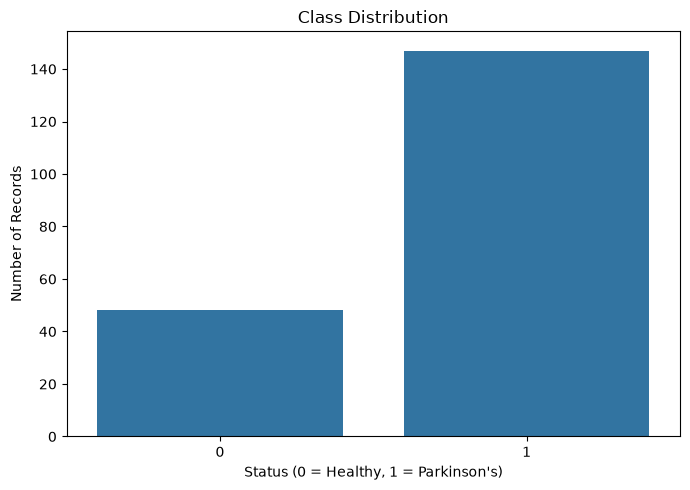

In [3]:
plt.figure(figsize=(7, 5))

sns.countplot(x=y)

plt.title("Class Distribution")
plt.xlabel("Status (0 = Healthy, 1 = Parkinson's)")
plt.ylabel("Number of Records")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

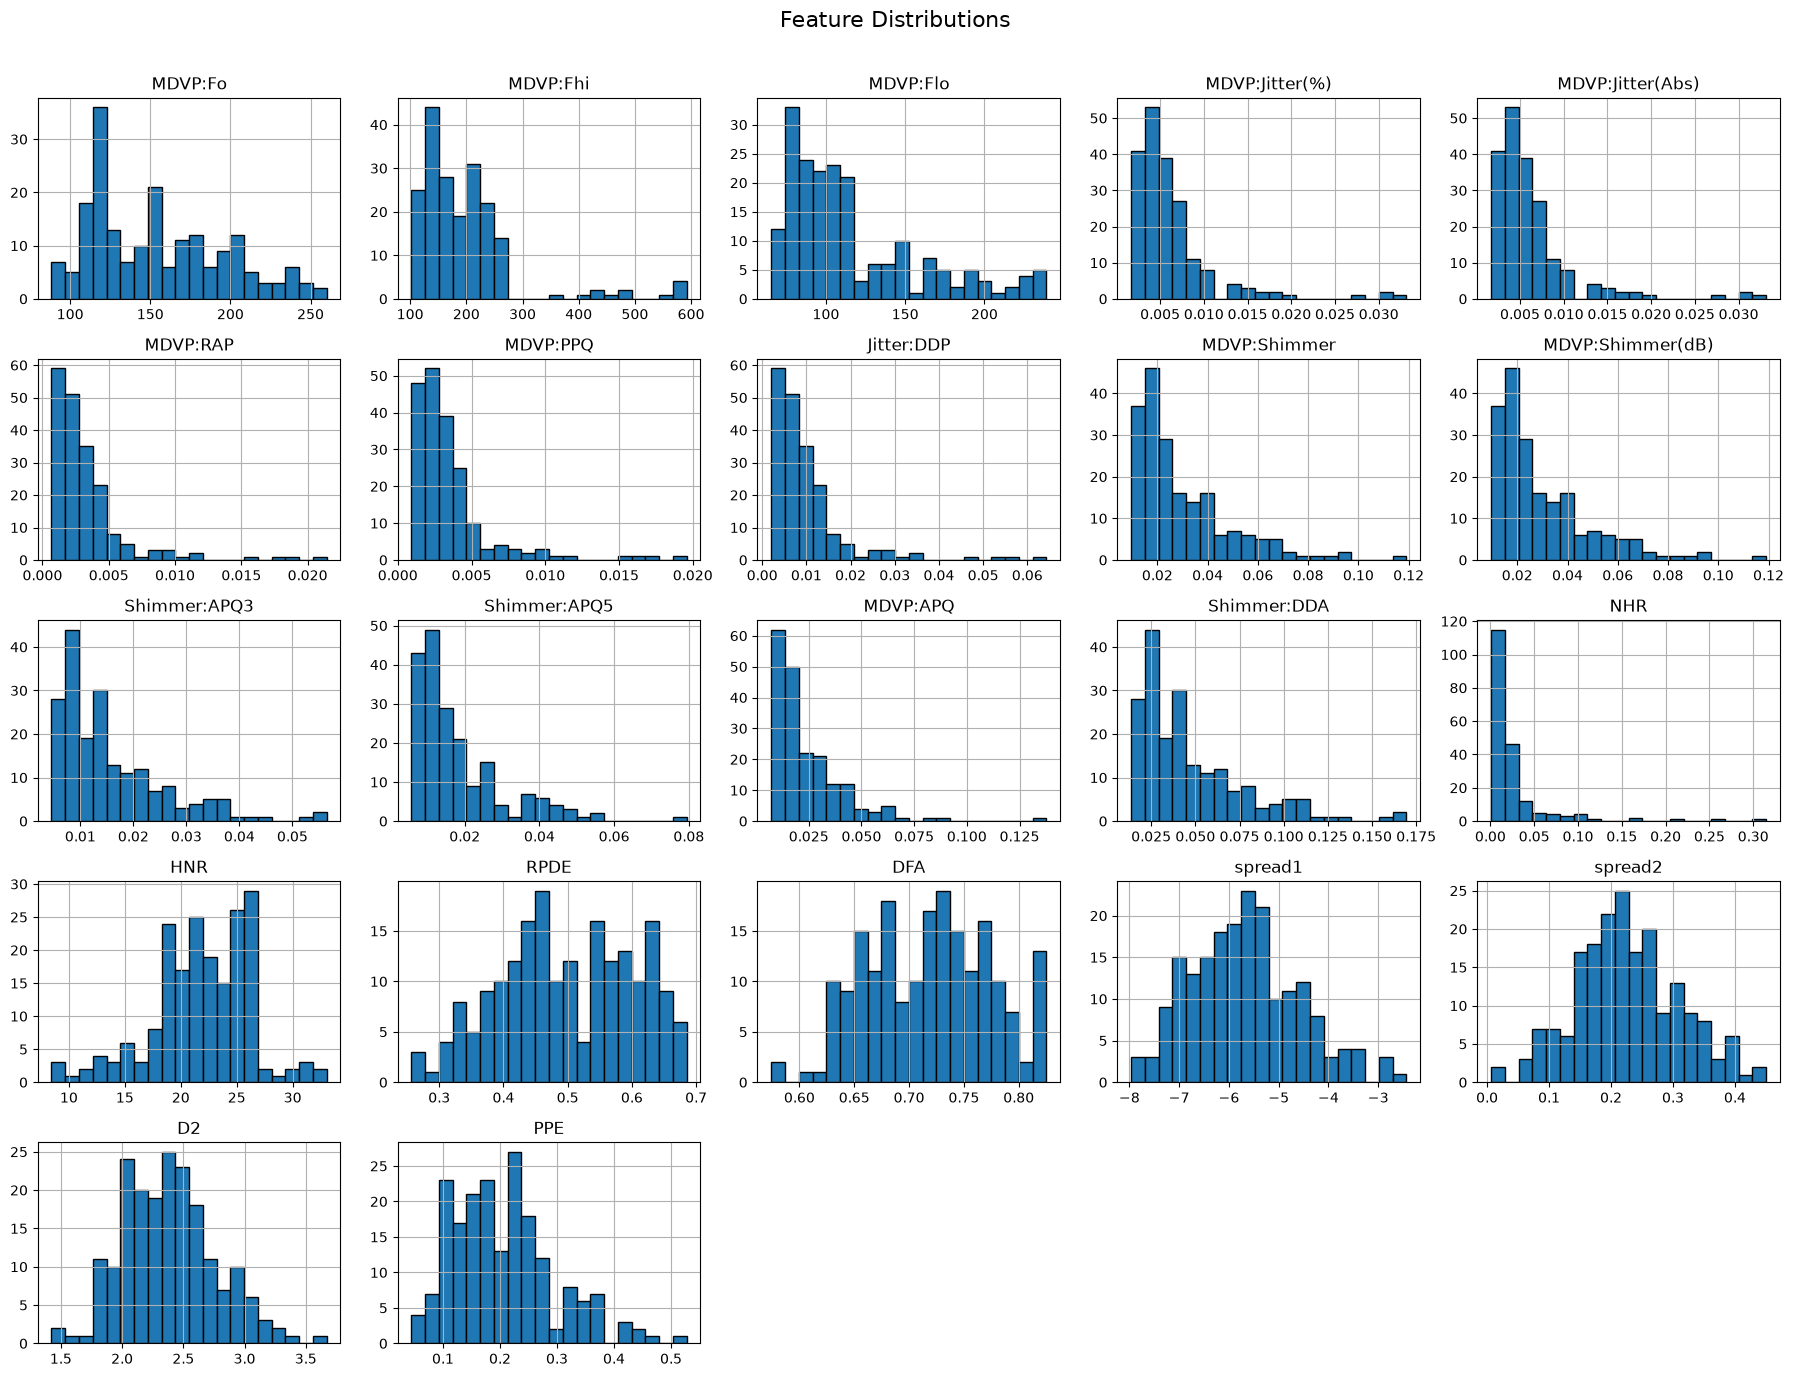

In [4]:
# Feature distributions

X.hist(
    figsize=(18, 14),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    "../outputs/figures/feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

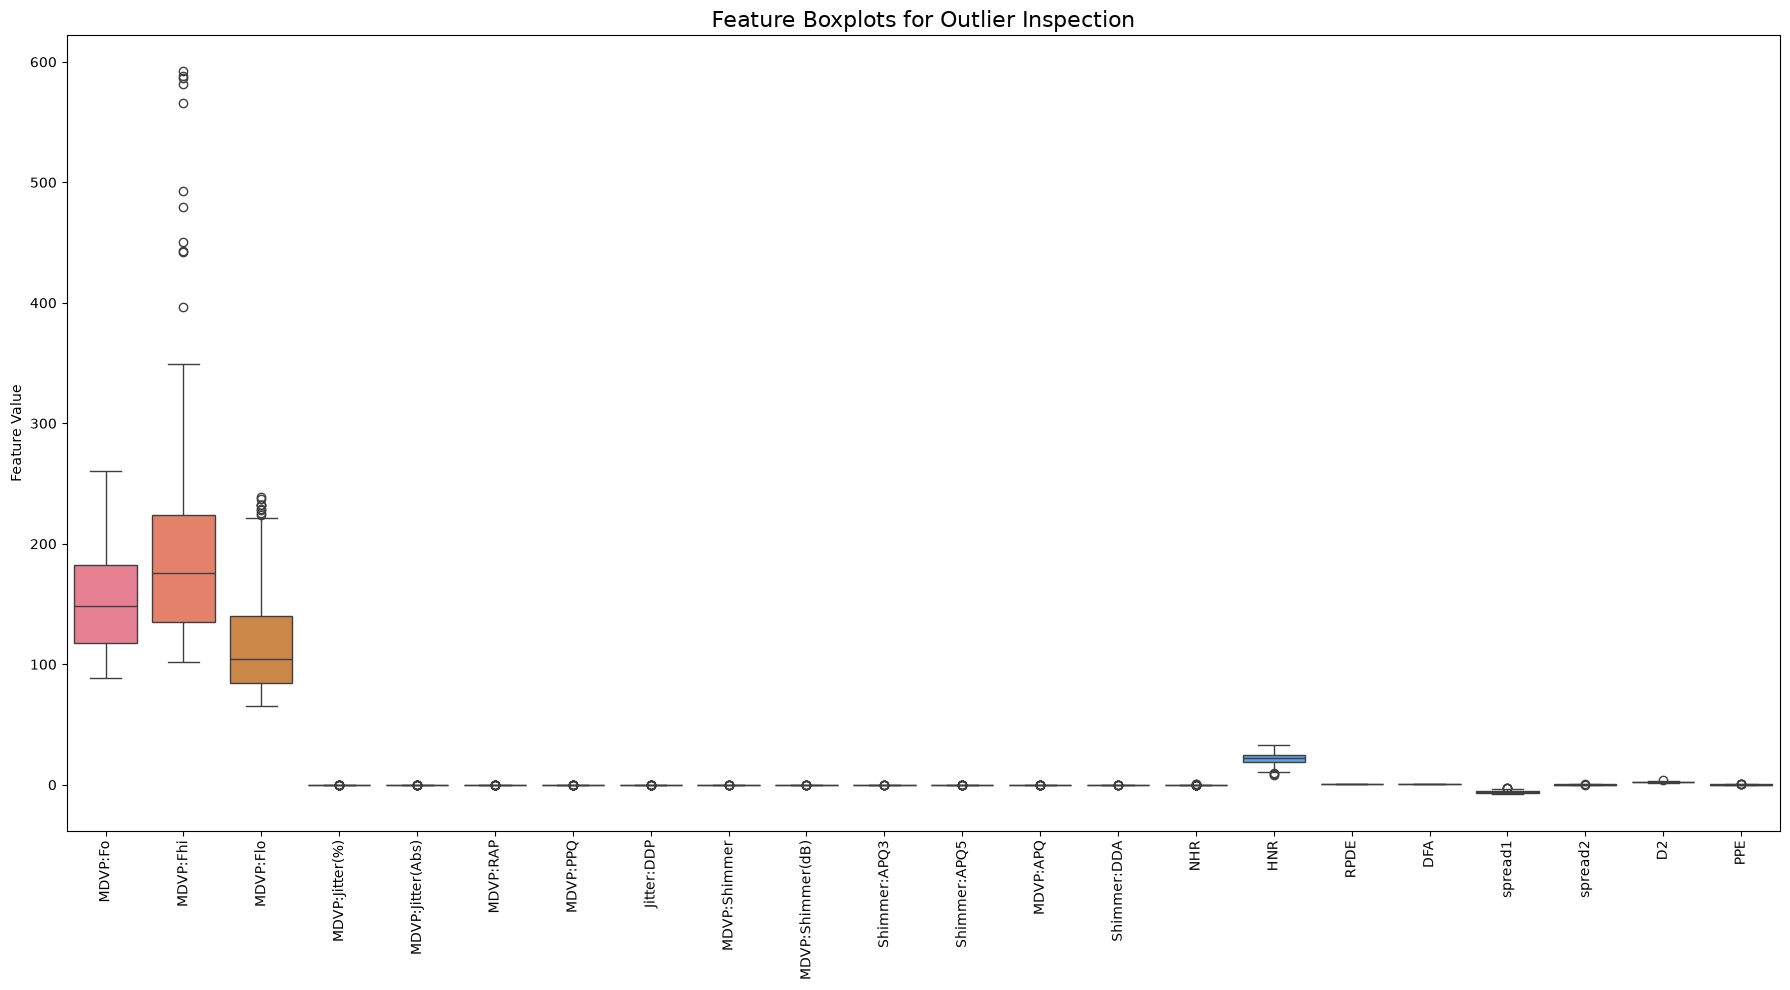

In [5]:
# Boxplots for outlier inspection

plt.figure(figsize=(18, 10))

sns.boxplot(data=X)

plt.title("Feature Boxplots for Outlier Inspection", fontsize=16)
plt.xticks(rotation=90)
plt.ylabel("Feature Value")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/feature_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

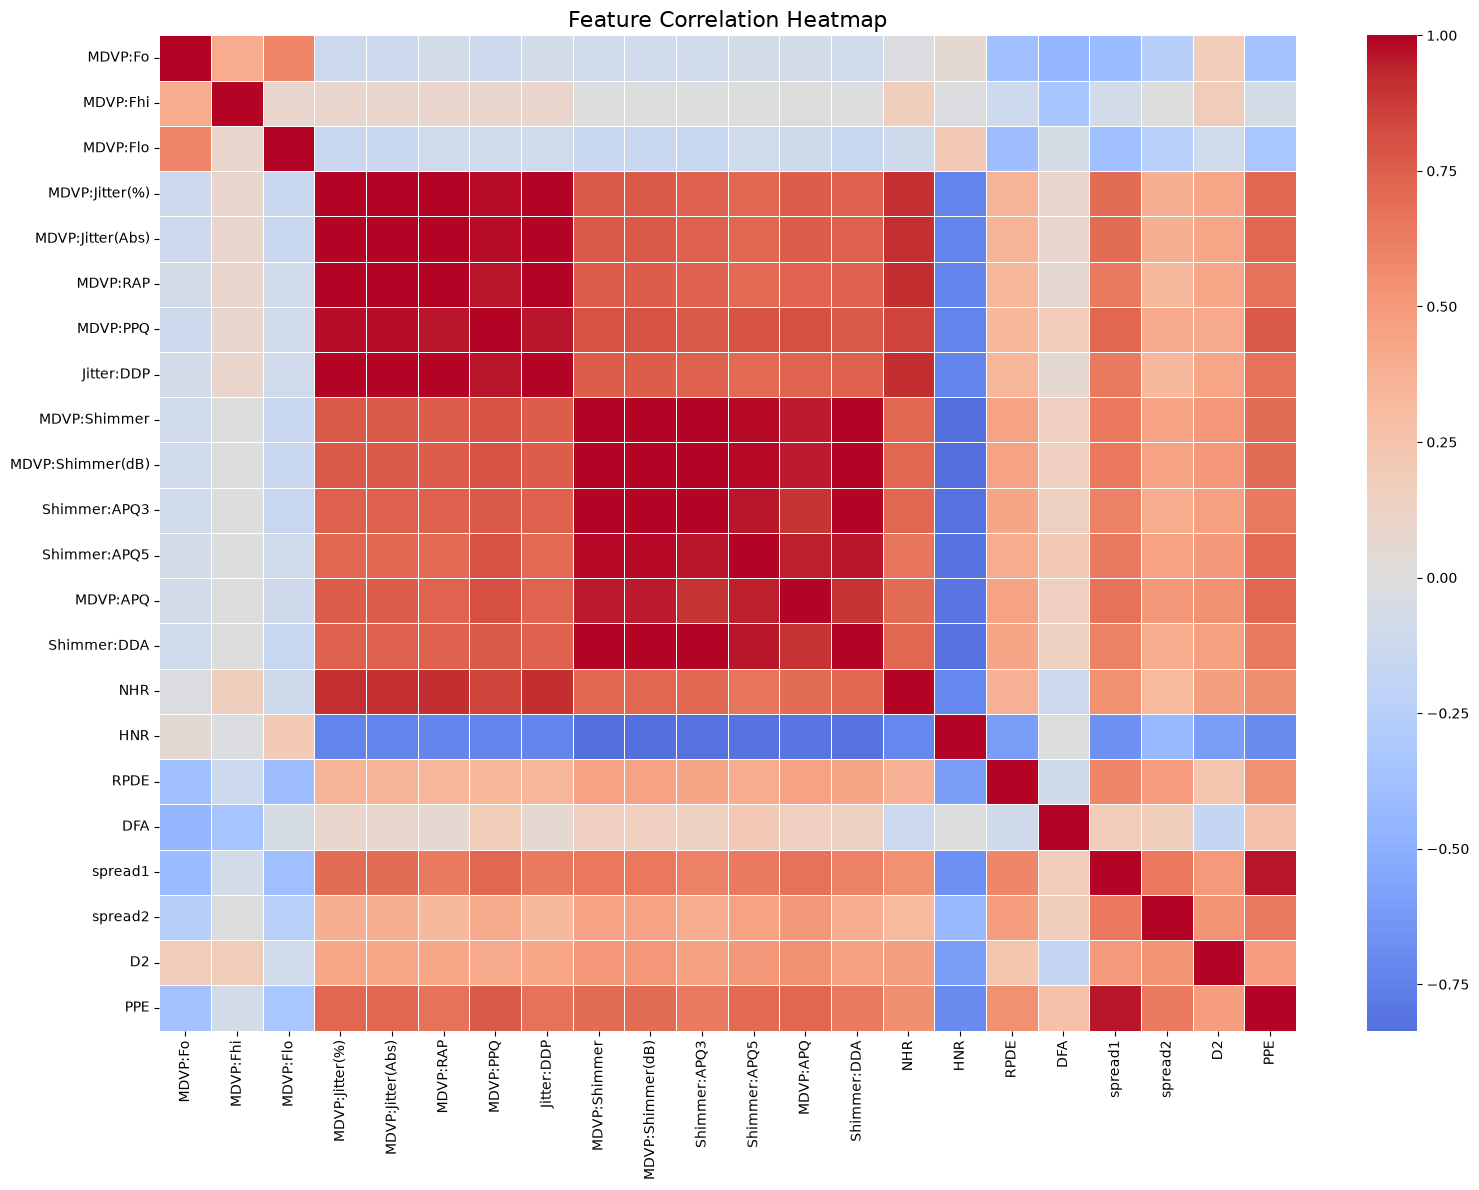

In [6]:
# Correlation heatmap

plt.figure(figsize=(16, 12))

correlation_matrix = X.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap", fontsize=16)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
# Numerical summary of the features

summary = X.describe().T

summary

,count,mean,std,min,25%,50%,75%,max
MDVP:Fo,195.0,154.228641,41.390065,88.333000,117.572000,148.790000,182.769000,260.105000
MDVP:Fhi,195.0,197.104918,91.491548,102.145000,134.862500,175.829000,224.205500,592.030000
MDVP:Flo,195.0,116.324631,43.521413,65.476000,84.291000,104.315000,140.018500,239.170000
MDVP:Jitter(%),195.0,0.006220,0.004848,0.001680,0.003460,0.004940,0.007365,0.033160
MDVP:Jitter(Abs),195.0,0.006220,0.004848,0.001680,0.003460,0.004940,0.007365,0.033160
MDVP:RAP,195.0,0.003306,0.002968,0.000680,0.001660,0.002500,0.003835,0.021440
MDVP:PPQ,195.0,0.003446,0.002759,0.000920,0.001860,0.002690,0.003955,0.019580
Jitter:DDP,195.0,0.009920,0.008903,0.002040,0.004985,0.007490,0.011505,0.064330
MDVP:Shimmer,195.0,0.029709,0.018857,0.009540,0.016505,0.022970,0.037885,0.119080
MDVP:Shimmer(dB),195.0,0.029709,0.018857,0.009540,0.016505,0.022970,0.037885,0.119080


In [8]:
# Compare feature means between Healthy and Parkinson's groups

group_means = df.groupby("status")[X.columns].mean().T

group_means.columns = ["Healthy (0)", "Parkinson's (1)"]

group_means

,Healthy (0),Parkinson's (1)
MDVP:Fo,181.937771,145.180762
MDVP:Fhi,223.636750,188.441463
MDVP:Flo,145.207292,106.893558
MDVP:Jitter(%),0.003866,0.006989
MDVP:Jitter(Abs),0.003866,0.006989
MDVP:RAP,0.001925,0.003757
MDVP:PPQ,0.002056,0.003900
Jitter:DDP,0.005776,0.011273
MDVP:Shimmer,0.017615,0.033658
MDVP:Shimmer(dB),0.017615,0.033658


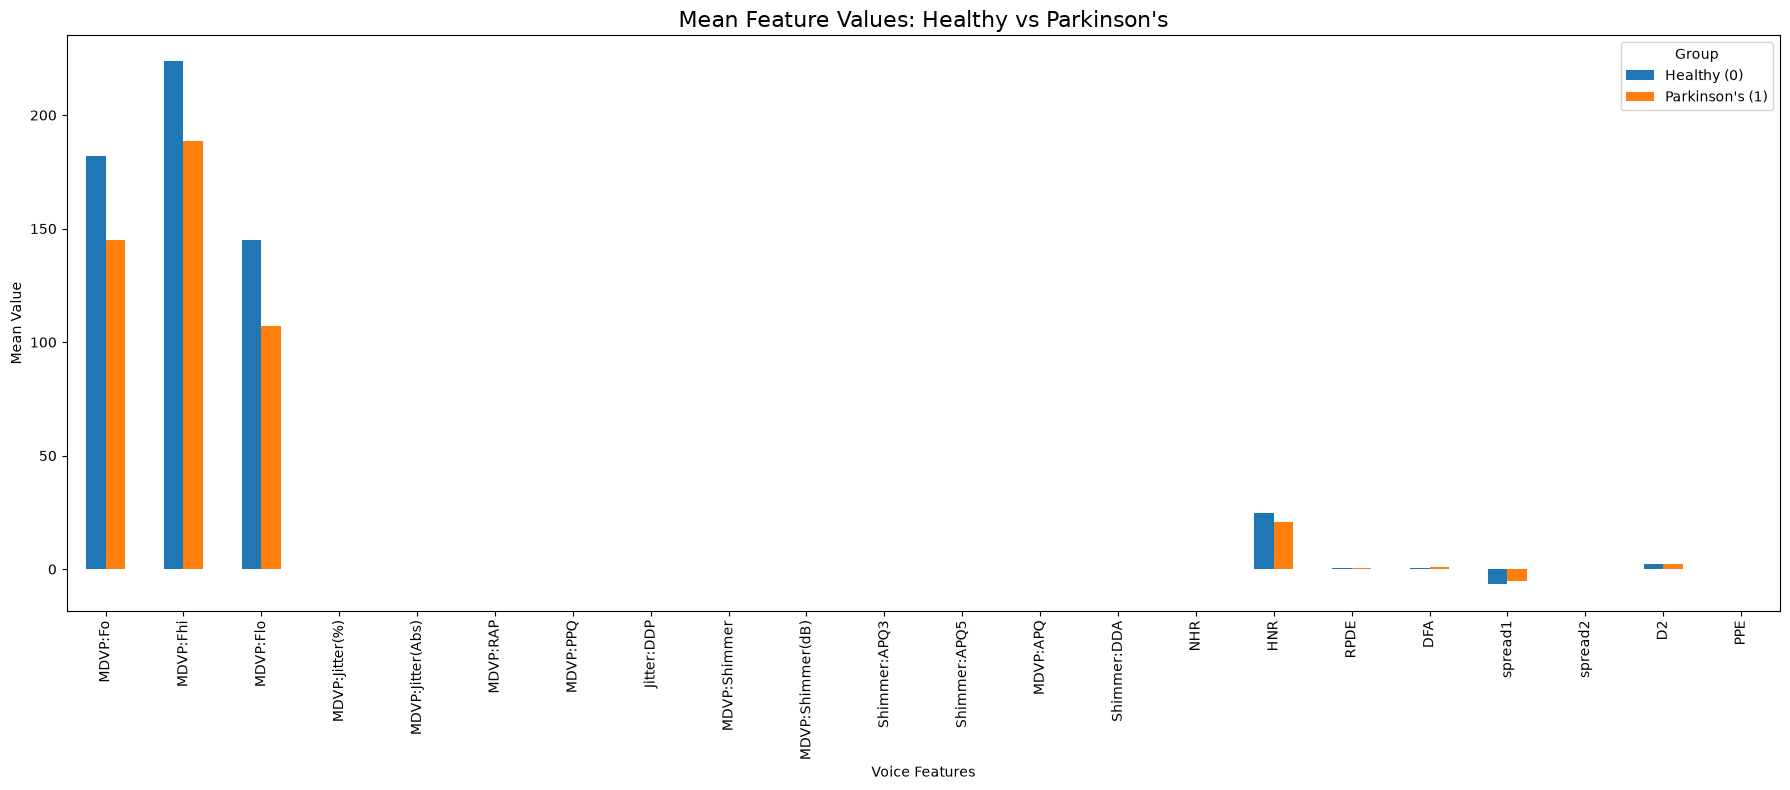

In [9]:
# Compare feature means between Healthy and Parkinson's groups

group_means.plot(
    kind="bar",
    figsize=(18, 8)
)

plt.title("Mean Feature Values: Healthy vs Parkinson's", fontsize=16)
plt.xlabel("Voice Features")
plt.ylabel("Mean Value")
plt.xticks(rotation=90)
plt.legend(title="Group")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/group_feature_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()